# Data collection (CRSP via WRDS)
Downloads everything once and caches it in `data/`. Re-running skips files that already exist.

- **Universe:** DJIA members, point-in-time, from `data/djia_constituents_tickers.csv`. CRSP keeps delisted stocks, so there's no survivorship bias.
- **SPY, TLT:** only for the market features (not traded).
- **VIX:** from CBOE (a feature only, not traded).

CRSP currently ends on **2025-12-31** (it updates once a year).

In [1]:
import os
import json
import pandas as pd
import wrds

os.makedirs('data', exist_ok=True)
START, END = '1999-01-01', '2025-12-31'   # 1999 = one year of warm-up for the 2000 features
db = wrds.Connection(wrds_username='bernaryerken')

Loading library list...


Done


## DJIA membership → CRSP PERMNO
Tickers get reused (e.g. `T` was old AT&T Corp until 2005, then SBC took the name). So each ticker is matched to the PERMNO that had it **on the snapshot date**.

The 1999-11-01 snapshot is kept: it's the index that was in force on 2000-01-01.

In [2]:
snap = pd.read_csv('data/djia_constituents_tickers.csv')
snap['ticker'] = snap['tickers'].apply(json.loads)
snap = snap.explode('ticker')[['date', 'ticker']]
snap = snap[(snap.date >= '1999-11-01') & (snap.date <= END)]
snap['date'] = pd.to_datetime(snap['date'])

names = db.raw_sql("""select distinct permno, ticker, namedt, nameenddt
                       from crsp.stocknames_v2 where ticker in %(t)s""",
                   params={'t': tuple(snap.ticker.unique())}, date_cols=['namedt', 'nameenddt'])
m = snap.merge(names, on='ticker')
m = m[(m.date >= m.namedt) & (m.date <= m.nameenddt)][['date', 'ticker', 'permno']]

# two tickers that CRSP didn't have on the snapshot day:
# HP traded as HWP until 2002; SBC switched to T 10 days after the 2005-11-21 snapshot
fixes = pd.DataFrame({'date': pd.to_datetime(['1999-11-01', '2005-11-21']),
                      'ticker': ['HPQ', 'T'], 'permno': [27828, 66093]})
membership = pd.concat([m, fixes])

# J.P. Morgan & Co merged into Chase on 2001-01-01; the merged JPMorgan Chase (a different PERMNO)
# kept the DJIA slot, but the CSV has no row for it, so add that snapshot
jpm = membership[membership.date == '1999-11-01'].assign(date=pd.Timestamp('2001-01-02'))
jpm.loc[jpm.permno == 48071, 'permno'] = 47896
membership = pd.concat([membership, jpm]).sort_values(['date', 'ticker']).reset_index(drop=True)
membership['permno'] = membership['permno'].astype(int)

assert (membership.groupby('date').size() == 30).all()   # every snapshot has exactly 30 stocks
membership.to_parquet('data/membership.parquet')
membership.groupby('date').size()

date
1999-11-01    30
2001-01-02    30
2003-01-27    30
2004-04-08    30
2005-11-21    30
2008-02-19    30
2008-09-22    30
2009-06-08    30
2012-09-24    30
2013-09-23    30
2015-03-19    30
2017-09-01    30
2018-06-26    30
2019-04-02    30
2020-04-06    30
2020-08-31    30
2024-02-26    30
2024-11-08    30
dtype: int64

## Daily prices (DJIA stocks + SPY, TLT)

In [3]:
ETFS = ['SPY', 'TLT']   # market return and stock-bond correlation

if not os.path.exists('data/prices.parquet'):
    etf = db.raw_sql("""select distinct permno, ticker from crsp.stocknames_v2
                         where ticker in %(t)s and nameenddt >= %(end)s""",
                     params={'t': tuple(ETFS), 'end': END})
    assert len(etf) == len(ETFS)
    permnos = tuple(int(p) for p in set(membership.permno) | set(etf.permno))

    # close = abs(dlyprc): CRSP stores a bid/ask midpoint as a negative price on no-trade days
    # ret = total return incl. dividends and delisting returns
    prices = db.raw_sql("""select permno, dlycaldt as date, ticker,
                                dlyopen as open, dlyhigh as high, dlylow as low, abs(dlyprc) as close,
                                dlyret as ret, dlyprcvol as dollar_vol, dlycumfacpr as cumfacpr
                         from crsp.dsf_v2
                         where permno in %(p)s and dlycaldt between %(start)s and %(end)s""",
                        params={'p': permnos, 'start': START, 'end': END}, date_cols=['date'])
    num = ['open', 'high', 'low', 'close', 'ret', 'dollar_vol', 'cumfacpr']
    prices[num] = prices[num].astype(float)   # WRDS gives nullable types; numpy wants plain floats
    prices['permno'] = prices['permno'].astype(int)
    prices.to_parquet('data/prices.parquet')

prices = pd.read_parquet('data/prices.parquet')
prices.groupby('permno').agg(ticker=('ticker', 'last'), first=('date', 'min'), last=('date', 'max')).head()

,ticker,first,last
permno,,,
10107,MSFT,1999-01-04,2025-12-31
10145,HON,1999-01-04,2025-12-31
10401,T,1999-01-04,2005-11-21
11308,KO,1999-01-04,2025-12-31
11703,DD,1999-01-04,2017-09-01


## VIX // maybe later

In [4]:
if not os.path.exists('data/vix.parquet'):
    vix = db.raw_sql("""select date, vix from cboe.cboe
                         where date between %(start)s and %(end)s and vix is not null""",
                     params={'start': START, 'end': END}, date_cols=['date'])
    vix['vix'] = vix['vix'].astype(float)
    vix = vix.drop_duplicates('date')   # CBOE has a couple of exact duplicate days
    vix.to_parquet('data/vix.parquet')

vix = pd.read_parquet('data/vix.parquet')
vix.tail()

,date,vix
6816,2025-12-24,13.47
6817,2025-12-26,13.60
6818,2025-12-29,14.20
6819,2025-12-30,14.33
6820,2025-12-31,14.95


## Risk-free rate
Daily return of the 1-month T-bill, from the Fama-French factors. Used to compute the Sharpe ratio (subtract it from daily returns) and as *r* when pricing options.

<Axes: title={'center': 'T-bill rate (annualised)'}, xlabel='date'>

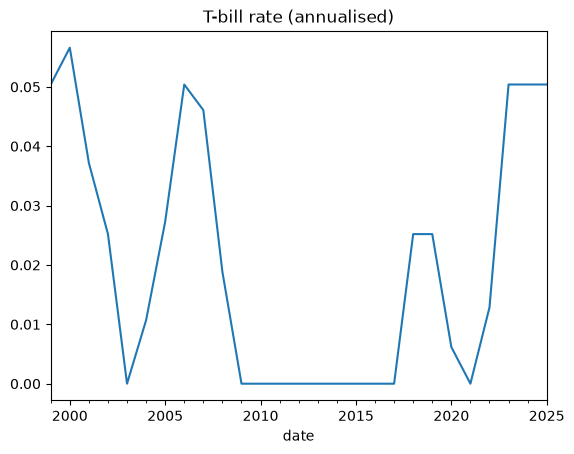

In [5]:
if not os.path.exists('data/rf.parquet'):
    rf = db.raw_sql("""select date, rf from ff.factors_daily
                        where date between %(start)s and %(end)s""",
                    params={'start': START, 'end': END}, date_cols=['date'])
    rf['rf'] = rf['rf'].astype(float)
    rf.to_parquet('data/rf.parquet')

rf = pd.read_parquet('data/rf.parquet')
(rf.set_index('date').rf * 252).resample('YE').mean().plot(title='T-bill rate (annualised)')